# Bundle Adjustment Example

From https://scipy-cookbook.readthedocs.io/items/bundle_adjustment.html

In [1]:
import urllib
import bz2
import os
import numpy as np

In [2]:
BASE_URL = "http://grail.cs.washington.edu/projects/bal/data/ladybug/"
FILE_NAME = "problem-49-7776-pre.txt.bz2"
URL = BASE_URL + FILE_NAME
DIR_NAME = "data"

file_path = os.path.join(DIR_NAME, FILE_NAME)


if not os.path.isfile(file_path):
    urllib.request.urlretrieve(URL, file_path)

In [3]:
def read_bal_data(file_name):
    with bz2.open(file_name, "rt") as file:
        n_cameras, n_points, n_observations = map(
            int, file.readline().split())

        camera_indices = np.empty(n_observations, dtype=int)
        point_indices = np.empty(n_observations, dtype=int)
        points_2d = np.empty((n_observations, 2))

        for i in range(n_observations):
            camera_index, point_index, x, y = file.readline().split()
            camera_indices[i] = int(camera_index)
            point_indices[i] = int(point_index)
            points_2d[i] = [float(x), float(y)]

        camera_params = np.empty(n_cameras * 9)
        for i in range(n_cameras * 9):
            camera_params[i] = float(file.readline())
        camera_params = camera_params.reshape((n_cameras, -1))

        points_3d = np.empty(n_points * 3)
        for i in range(n_points * 3):
            points_3d[i] = float(file.readline())
        points_3d = points_3d.reshape((n_points, -1))

    return camera_params, points_3d, camera_indices, point_indices, points_2d

In [4]:
camera_params, points_3d, camera_indices, point_indices, points_2d = read_bal_data(file_path)

In [5]:
n_cameras = camera_params.shape[0]
n_points = points_3d.shape[0]

n = 9 * n_cameras + 3 * n_points
m = 2 * points_2d.shape[0]

print("n_cameras: {}".format(n_cameras))
print("n_points: {}".format(n_points))
print("Total number of parameters: {}".format(n))
print("Total number of residuals: {}".format(m))

n_cameras: 49
n_points: 7776
Total number of parameters: 23769
Total number of residuals: 63686


In [6]:
def rotate(points, rot_vecs):
    """Rotate points by given rotation vectors.
    
    Rodrigues' rotation formula is used.
    """
    theta = np.linalg.norm(rot_vecs, axis=1)[:, np.newaxis]
    with np.errstate(invalid='ignore'):
        v = rot_vecs / theta
        v = np.nan_to_num(v)
    dot = np.sum(points * v, axis=1)[:, np.newaxis]
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)

    return cos_theta * points + sin_theta * np.cross(v, points) + dot * (1 - cos_theta) * v

In [7]:
def project(points, camera_params):
    """Convert 3-D points to 2-D by projecting onto images."""
    points_proj = rotate(points, camera_params[:, :3])
    points_proj += camera_params[:, 3:6]
    points_proj = -points_proj[:, :2] / points_proj[:, 2, np.newaxis]
    f = camera_params[:, 6]
    k1 = camera_params[:, 7]
    k2 = camera_params[:, 8]
    n = np.sum(points_proj**2, axis=1)
    r = 1 + k1 * n + k2 * n**2
    points_proj *= (r * f)[:, np.newaxis]
    return points_proj

In [8]:
def fun(params, n_cameras, n_points, camera_indices, point_indices, points_2d):
    """Compute residuals.
    
    `params` contains camera parameters and 3-D coordinates.
    """
    camera_params = params[:n_cameras * 9].reshape((n_cameras, 9))
    points_3d = params[n_cameras * 9:].reshape((n_points, 3))
    points_proj = project(points_3d[point_indices], camera_params[camera_indices])
    return (points_proj - points_2d).ravel()

In [9]:
from scipy.sparse import lil_matrix

def bundle_adjustment_sparsity(n_cameras, n_points, camera_indices, point_indices):
    m = camera_indices.size * 2
    n = n_cameras * 9 + n_points * 3
    A = lil_matrix((m, n), dtype=int)

    i = np.arange(camera_indices.size)
    for s in range(9):
        A[2 * i, camera_indices * 9 + s] = 1
        A[2 * i + 1, camera_indices * 9 + s] = 1

    for s in range(3):
        A[2 * i, n_cameras * 9 + point_indices * 3 + s] = 1
        A[2 * i + 1, n_cameras * 9 + point_indices * 3 + s] = 1

    return A

Text(0.5, 0, 'Residual')

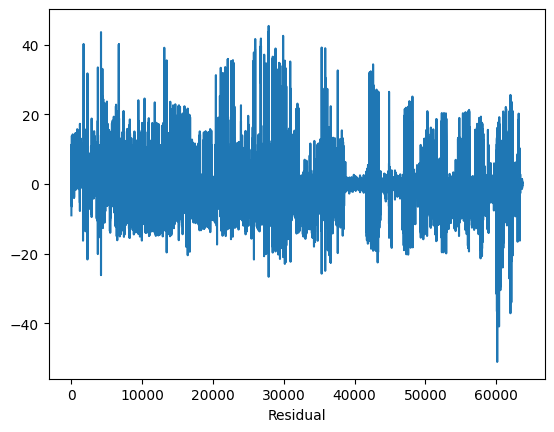

In [10]:
import matplotlib.pyplot as plt

x0 = np.hstack((camera_params.ravel(), points_3d.ravel()))
f0 = fun(x0, n_cameras, n_points, camera_indices, point_indices, points_2d)
plt.plot(f0)
plt.xlabel('Residual')

In [11]:
A = bundle_adjustment_sparsity(n_cameras, n_points, camera_indices, point_indices)

In [12]:
import time
from scipy.optimize import least_squares

t0 = time.time()
res = least_squares(fun, x0, jac_sparsity=A, verbose=2, x_scale='jac', ftol=1e-4, method='trf',
                    args=(n_cameras, n_points, camera_indices, point_indices, points_2d))
t1 = time.time()
print("Optimization took {0:.0f} seconds".format(t1 - t0))


   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         8.5091e+05                                    8.57e+06    
       1              3         5.0985e+04      8.00e+05       1.46e+02       1.15e+06    
       2              4         1.6077e+04      3.49e+04       2.59e+01       2.43e+05    
       3              5         1.4163e+04      1.91e+03       2.86e+02       1.21e+05    
       4              7         1.3695e+04      4.67e+02       1.32e+02       2.51e+04    
       5              8         1.3481e+04      2.14e+02       2.24e+02       1.54e+04    
       6              9         1.3436e+04      4.54e+01       3.18e+02       2.73e+04    
       7             10         1.3422e+04      1.38e+01       6.84e+01       2.21e+03    
       8             11         1.3418e+04      3.71e+00       1.28e+02       7.92e+03    
       9             12         1.3414e+04      4.21e+00       2.64e+01       6.21e+02    

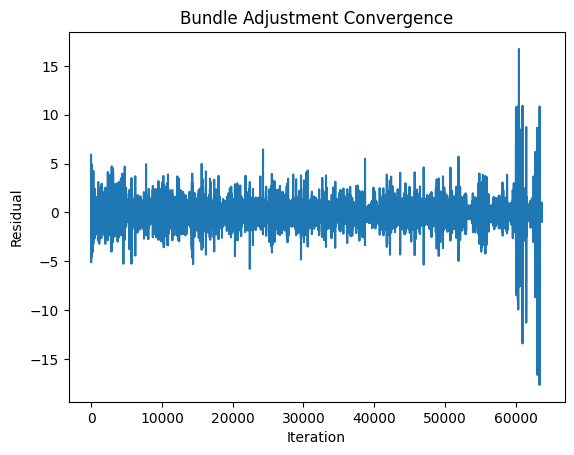

In [13]:
plt.plot(res.fun)
plt.xlabel('Iteration')
plt.ylabel('Residual')
plt.title('Bundle Adjustment Convergence')
plt.show()

Now, lets apply BA to calculate the camera positions and the 3d point positions of the ED experiment.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
from argparse import ArgumentParser
from tqdm import trange

sys.path.append(os.getcwd()+"/..")

# Placeholder for your custom functions
from simulation.utils import (
    generate_unit_cell_anisotropy, 
    lattice_parameters_reciprocal,
    reciprocal_lattice_vectors, 
    random_rotate_vectors,
    generate_reciprocal_lattice,
    fibonacci_orientations,
    orientations_to_indices,
    align_reciprocal_lattice,
    simulate_diffraction_experiment,
    project_reflections_2D,
    remove_random_pairs,
    add_random_pairs,
    add_noise,
    shift_points,
    save_parameters,
    is_linear_combination,
    find_linear_independent
)


Generated unit cell parameters:
a = 8.189 Å
b = 10.180 Å
c = 7.634 Å
alpha = 108.21°
beta = 103.97°
gamma = 117.42°
Reciprocal lattice parameters:
astar = 0.200
bstar = 0.167
cstar = 0.143
alphastar = 90.000°
betastar = 90.000°
gammastar = 90.000°
True


In [15]:
target_volume = 500
volume_error = 100
a_range = [3.5, 15]
b_range = [4, 30]
c_range = [5, 45]
alpha_range = [90, 120]
beta_range = [90, 120]
gamma_range = [90, 120]
anisotropy = 1.5
resolution = 0.85
wavelength = 0.0407
excitation_error = 0.015
detector_distance = 0
edge = 1.5
fraction_limit_missing = 0.03
fraction_limit_additional = 0.05
noise_level = 0.0012
max_shift = 0.01
N = 1000
zonal_sample_threshold = 0.9
zonal_segmentation_threshold = 0.4
output_folder = "output"

# Generate unit cell parameters
a, b, c, alpha, beta, gamma = generate_unit_cell_anisotropy(
    target_volume, a_range, b_range, c_range, alpha_range, beta_range, gamma_range, volume_error, anisotropy
)

# Round the parameters
a = round(a, 3)
b = round(b, 3)
c = round(c, 3)
alpha = round(alpha, 2)
beta = round(beta, 2)
gamma = round(gamma, 2)

# Display results
print(f"Generated unit cell parameters:")
print(f"a = {a:.3f} Å")
print(f"b = {b:.3f} Å")
print(f"c = {c:.3f} Å")
print(f"alpha = {alpha:.2f}°")
print(f"beta = {beta:.2f}°")
print(f"gamma = {gamma:.2f}°")


# Compute reciprocal lattice parameters
astar, bstar, cstar, alphastar, betastar, gammastar = lattice_parameters_reciprocal(a, b, c, alpha, beta, gamma)
v1, v2, v3 = reciprocal_lattice_vectors(astar, bstar, cstar, alphastar, betastar, gammastar)

astar_rot, bstar_rot, cstar_rot = random_rotate_vectors(v1, v2, v3)

# Generate reciprocal lattice reflections
hkl_list, reflections = generate_reciprocal_lattice(v1, v2, v3, resolution)

orientations = fibonacci_orientations(N)
indices = orientations_to_indices(orientations, astar_rot, bstar_rot, cstar_rot)
# Parameters
R = 1 / wavelength

# Compute Ewald sphere
theta, phi = np.meshgrid(np.linspace(0, np.pi, 50), np.linspace(0, 2 * np.pi, 100))
X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

# Shift the sphere to the Ewald center
X = X + 0
Y = Y + 0
Z = Z + R


Generated unit cell parameters:
a = 10.290 Å
b = 8.936 Å
c = 9.946 Å
alpha = 119.15°
beta = 116.71°
gamma = 112.05°


In [16]:
i = 0
rotated_reflections = align_reciprocal_lattice(reflections, orientations[i, :])
ewald_sphere, diffraction_spots, hkl_included = simulate_diffraction_experiment(hkl_list, rotated_reflections, wavelength, excitation_error)

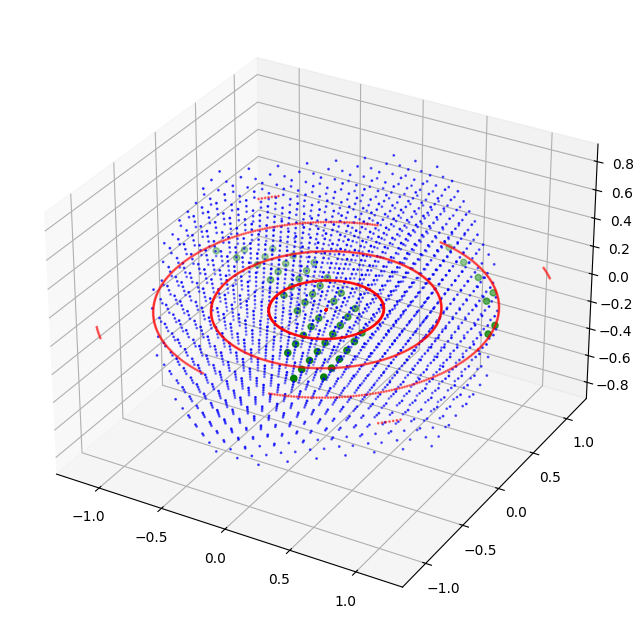

In [17]:
import matplotlib.pyplot as plt

reflection_bounds = np.concatenate([np.min(reflections, axis=0), np.max(reflections, axis=0)])
ewald_sphere_viz = ewald_sphere[(ewald_sphere[:, 0] >= reflection_bounds[0]) & (ewald_sphere[:, 0] <= reflection_bounds[3]) &
                             (ewald_sphere[:, 1] >= reflection_bounds[1]) & (ewald_sphere[:, 1] <= reflection_bounds[4]) &
                             (ewald_sphere[:, 2] >= reflection_bounds[2]) & (ewald_sphere[:, 2] <= reflection_bounds[5])]

ax = plt.figure(figsize=(8, 8)).add_subplot(111, projection='3d')
ax.scatter(reflections[:, 0], reflections[:, 1], reflections[:, 2], color='blue', label='Reflections', s=1)
ax.scatter(ewald_sphere_viz[:, 0], ewald_sphere_viz[:, 1], ewald_sphere_viz[:, 2], color='red', label='Ewald Sphere', s=1, alpha=0.5)
ax.scatter(diffraction_spots[:, 0], diffraction_spots[:, 1], diffraction_spots[:, 2], color='green', label='Diffraction Spots', s=20)

In [18]:
camera_direction = orientations[i, :]
camera_position = camera_direction * 1 / wavelength * 0.1
center = np.array([0.0, 0.0, 0.0])
dir_vec = center - camera_position
dir_unit = dir_vec / np.linalg.norm(dir_vec)

z_axis = np.array([0.0, 0.0, 1.0])
v = np.cross(z_axis, dir_unit)
s = np.linalg.norm(v)
c = np.dot(z_axis, dir_unit)
if s < 1e-8:
    rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
else:
    K = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
    rot_mat = np.eye(3) + K + K @ K * ((1.0 - c) / (s**2))

camera_extrinsics = np.eye(4)
camera_extrinsics[:3, :3] = rot_mat
camera_extrinsics[:3, 3] = camera_position

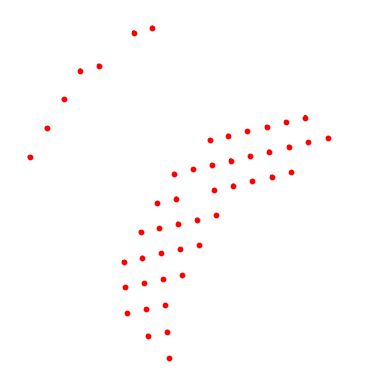

In [36]:
import cv2 

canvas_size = 1000
focal_length = canvas_size * 1
K_intrinsic = np.array([[focal_length, 0, canvas_size // 2], [0, focal_length, canvas_size // 2], [0, 0, 1]])
T_extrinsics = np.linalg.inv(camera_extrinsics)

world_pts_homogeneous = np.hstack([diffraction_spots, np.ones((diffraction_spots.shape[0], 1))])
projected_pts_homogeneous = ((K_intrinsic @ T_extrinsics[:3, :]) @ world_pts_homogeneous.T).T
projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
depth = projected_pts_homogeneous[:, 2]


canvas = np.ones((canvas_size, canvas_size), dtype=np.uint8) * 255
depth_map = np.full((canvas_size, canvas_size), np.inf)

meshgrid_x, meshgrid_y = np.meshgrid(np.arange(canvas_size), np.arange(canvas_size))
meshgrid_points = np.stack([meshgrid_x, meshgrid_y], axis=-1).reshape(-1, 2)
for x, y, d in zip(projected_x, projected_y, depth):
    if 0 <= x < canvas.shape[1] and 0 <= y < canvas.shape[0]:
        circle_radius = 5
        circle_center = np.array([x, y], dtype=np.int32)
        canvas[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = 0
        depth_map[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = d
plt.imshow(canvas, cmap='gray')
plt.axis('off')
plt.scatter(projected_x, projected_y, color='red', s=10)


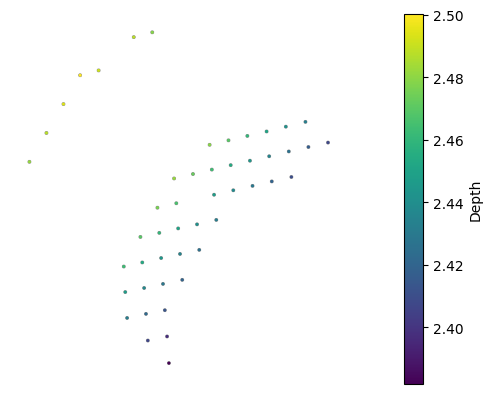

In [37]:
plt.imshow(depth_map, cmap='viridis')
plt.colorbar(label='Depth')
plt.axis('off')
plt.show()

We can actually estimate the depth of each pixel, by its distance from the camera (The Edwald Sphere).

In [38]:
def project_to_world(projected_x, projected_y, depth, intrinsics, extrinsics):
    projected_pts_homogeneous = np.stack([projected_x * depth, projected_y * depth, depth, np.ones_like(depth)], axis=-1)
    intrinsic_hom = np.eye(4)
    intrinsic_hom[:3, :3] = intrinsics
    world_pts_homogeneous = np.linalg.inv(intrinsic_hom @ extrinsics) @ projected_pts_homogeneous.T
    world_pts_homogeneous /= world_pts_homogeneous[3, :]
    return world_pts_homogeneous[:3, :].T

original_world_pts = project_to_world(projected_x, projected_y, depth, K_intrinsic, T_extrinsics)
constant_depth_world_pts = project_to_world(projected_x, projected_y, np.ones_like(projected_x)*1/wavelength*0.1, K_intrinsic, T_extrinsics)

print("Difference between original world points and diffraction spots:")
print(np.mean(original_world_pts - diffraction_spots))
print("Difference between constant depth world points and diffraction spots:")
print(np.mean(constant_depth_world_pts - diffraction_spots))

Difference between original world points and diffraction spots:
-8.952485979487279e-17
Difference between constant depth world points and diffraction spots:
-0.005042805500824123


We see that an estimation of constant depth is on average not far off from the actual positions of the points.

In [39]:
def project_points(points, intrinsics, extrinsics):
    world_pts_homogeneous = np.hstack([points, np.ones((points.shape[0], 1))])
    projected_pts_homogeneous = ((intrinsics @ extrinsics[:3, :]) @ world_pts_homogeneous.T).T
    projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
    projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
    depth = projected_pts_homogeneous[:, 2]
    return projected_x, projected_y, depth

def residual(points, projected_x, projected_y, depth, intrinsics, extrinsics):
    projected_x_calc, projected_y_calc, depth_calc = project_points(points, intrinsics, extrinsics)
    return np.stack([projected_x_calc - projected_x, projected_y_calc - projected_y, depth_calc - depth], axis=-1)

np.sum(residual(diffraction_spots, projected_x, projected_y, depth, K_intrinsic, T_extrinsics))

np.float64(0.0)

Since all cameras are equidistant and have the same intrinsic parameters, we only azimuth and elivation of the spherical coordinates for all cameras. Also all points are calculated using the same edwald sphere only shifted by camera position, so we can calculate the projection using only `azimuth` and `elevtaion`.

In [45]:
def extrinsics_from_angles(azimuth, elevation, wavelength):
    camera_direction = np.array([
        np.cos(elevation) * np.cos(azimuth),
        np.cos(elevation) * np.sin(azimuth),
        np.sin(elevation)
    ])
    camera_position = camera_direction * 1 / wavelength * 0.1
    center = np.array([0.0, 0.0, 0.0])
    dir_vec = center - camera_position
    dir_unit = dir_vec / np.linalg.norm(dir_vec)

    z_axis = np.array([0.0, 0.0, 1.0])
    v = np.cross(z_axis, dir_unit)
    s = np.linalg.norm(v)
    c = np.dot(z_axis, dir_unit)
    if s < 1e-8:
        rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    else:
        K = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
        rot_mat = np.eye(3) + K + K @ K * ((1.0 - c) / (s**2))

    camera_extrinsics = np.eye(4)
    camera_extrinsics[:3, :3] = rot_mat
    camera_extrinsics[:3, 3] = camera_position

    T_extrinsics = np.linalg.inv(camera_extrinsics)
    return T_extrinsics

def azimuth_elevation_from_extrinsics(T_extrinsics):
    camera_position = T_extrinsics[:3, 3]
    camera_direction = -T_extrinsics[:3, :3].T @ np.array([0.0, 0.0, 1.0])
    azimuth = np.arctan2(camera_direction[1], camera_direction[0])
    elevation = np.arcsin(camera_direction[2] / np.linalg.norm(camera_direction))
    return azimuth, elevation

azimuth, elevation = azimuth_elevation_from_extrinsics(T_extrinsics)
print(f"Azimuth: {np.degrees(azimuth):.2f} degrees, Elevation: {np.degrees(elevation):.2f} degrees")

calculated_T_extrinsics = extrinsics_from_angles(azimuth, elevation, wavelength)

print("Difference between original T_extrinsics and calculated T_extrinsics:")
print(np.mean(T_extrinsics - calculated_T_extrinsics))

Azimuth: -137.51 degrees, Elevation: 86.38 degrees
Difference between original T_extrinsics and calculated T_extrinsics:
1.6508916428820956e-17


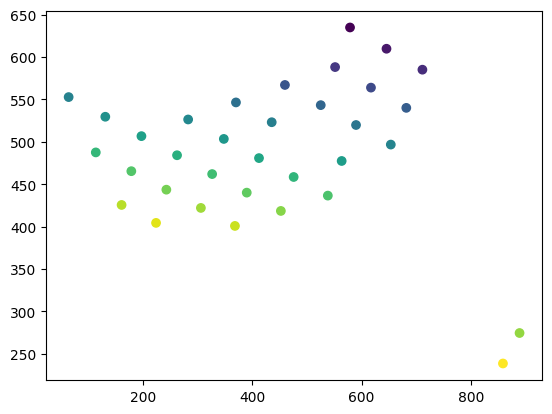

In [69]:
def calculate_projection(points, T_extrinsics, K_intrinsic, radius=1e-3, tolerance=1e-6):
    projected_x, projected_y, depth = project_points(points, K_intrinsic, T_extrinsics)
    # cut using radius of edwald sphere
    idx = np.where(np.logical_and(depth < radius + tolerance, depth > radius - tolerance))[0]
    return projected_x[idx], projected_y[idx], depth[idx]

azimuth = np.pi/4 + 0.6
elevation = np.pi/6 + 1.4
T_extrinsics = extrinsics_from_angles(azimuth, elevation, wavelength)
projected_x, projected_y, depth = calculate_projection(diffraction_spots, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error / 0.1)

plt.scatter(projected_x, projected_y, c=depth, cmap='viridis')

array([[-0.794 , -0.0639,  0.8043],
       [-0.9314, -0.0479,  0.6033],
       [-0.7873,  0.0081,  0.7038],
       ...,
       [ 0.7873, -0.0081, -0.7038],
       [ 0.9314,  0.0479, -0.6033],
       [ 0.794 ,  0.0639, -0.8043]], shape=(2344, 3))

In [ ]:
def calculate_matches(lattice, projected_x, projected_y, depth, T_extrinsics, K_intrinsic, radius=1e-3, tolerance=1e-6):
    world_pts = project_to_world(projected_x, projected_y, depth, K_intrinsic, T_extrinsics)
    matches = []
    for point in world_pts:
        distances = np.linalg.norm(lattice - point, axis=1)
        min_idx = np.argmin(distances)
        if distances[min_idx] < tolerance:
            matches.append((point, lattice[min_idx]))
    return matches

calculated_matches = calculate_matches(reflections, projected_x, projected_y, depth, T_extrinsics, K_intrinsic, radius=1 / wavelength * 0.1, tolerance=excitation_error / 0.1)
calculated_matches

[]

In [73]:
from scipy.optimize import minimize

def fun(params):
    azimuth, elevation = params
    T_extrinsics = extrinsics_from_angles(azimuth, elevation, wavelength)
    constant_depth = np.ones_like(projected_x) * 1 / wavelength * 0.1
    world_pts_homogeneous = project_to_world(projected_x, projected_y, constant_depth, K_intrinsic, T_extrinsics)
    return (world_pts_homogeneous - diffraction_spots).ravel()

minimize(fun, x0=[azimuth, elevation], method='Nelder-Mead', options={'maxiter': 1000, 'disp': True})

ValueError: operands could not be broadcast together with shapes (34,3) (49,3) 